In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [5]:
df = pd.read_csv("data_group2 (1).csv")
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sr_no   30000 non-null  int64  
 1   x       30000 non-null  float64
 2   y       30000 non-null  float64
 3   z       30000 non-null  float64
 4   f       30000 non-null  float64
dtypes: float64(4), int64(1)
memory usage: 1.1 MB
None
              sr_no             x             y             z             f
count  30000.000000  30000.000000  30000.000000  30000.000000  30000.000000
mean   14999.500000      0.327957     -0.302139      0.362420      7.462979
std     8660.398374     57.644180     57.811964     58.001685     40.848872
min        0.000000   -100.091211   -100.076668   -100.089426    -95.732340
25%     7499.750000    -49.464459    -50.589541    -50.297230    -18.488680
50%    14999.500000      0.544608     -0.316270      0.462674      7.605046
75%    22499.250000     50.361245     50.27926

In [6]:
X = df[['x', 'y', 'z']].values
y = df[['f']].values

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, shuffle=True
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, shuffle=True
)

In [8]:

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)


scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print("Training shape:", X_train_scaled.shape, y_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape, y_val_scaled.shape)
print("Test shape:", X_test_scaled.shape, y_test_scaled.shape)

Training shape: (21000, 3) (21000, 1)
Validation shape: (4500, 3) (4500, 1)
Test shape: (4500, 3) (4500, 1)


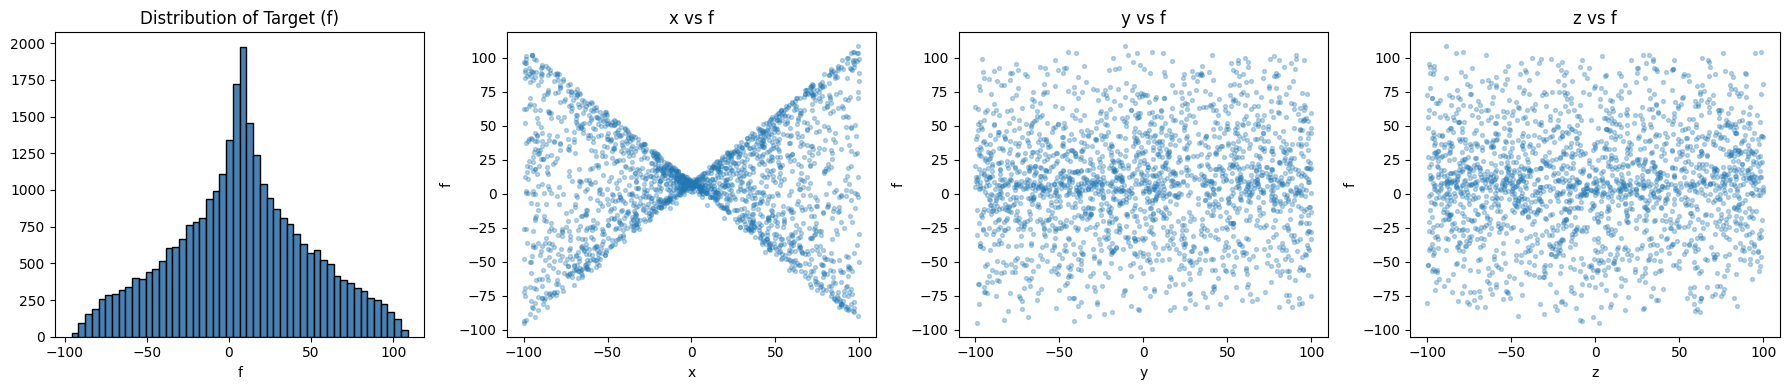

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))


axes[0].hist(df['f'], bins=50, color='steelblue', edgecolor='black')
axes[0].set_title("Distribution of Target (f)")
axes[0].set_xlabel("f")


sample_df = df.sample(2000, random_state=42)
for i, col in enumerate(['x', 'y', 'z']):
    axes[i+1].scatter(sample_df[col], sample_df['f'], alpha=0.3, s=8)
    axes[i+1].set_title(f"{col} vs f")
    axes[i+1].set_xlabel(col)
    axes[i+1].set_ylabel("f")

plt.tight_layout()
plt.show()

In [10]:

baseline_model = Sequential([
    Dense(64, activation='relu', input_shape=(3,)),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])

baseline_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)


history = baseline_model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,
    batch_size=64,
    verbose=1
)

y_val_pred_scaled = baseline_model.predict(X_val_scaled)
y_val_pred = scaler_y.inverse_transform(y_val_pred_scaled)


mse = mean_squared_error(y_val, y_val_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_val, y_val_pred)
r2 = r2_score(y_val, y_val_pred)

print(f"Baseline Validation Metrics -> MSE: {mse:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.0073 - mae: 0.7832 - val_loss: 0.9875 - val_mae: 0.7763
Epoch 2/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0031 - mae: 0.7811 - val_loss: 0.9880 - val_mae: 0.7760
Epoch 3/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0013 - mae: 0.7805 - val_loss: 0.9851 - val_mae: 0.7750
Epoch 4/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0007 - mae: 0.7800 - val_loss: 0.9872 - val_mae: 0.7756
Epoch 5/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0007 - mae: 0.7799 - val_loss: 0.9876 - val_mae: 0.7758
Epoch 6/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.9996 - mae: 0.7796 - val_loss: 0.9942 - val_mae: 0.7782
Epoch 7/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9999 - mae: 0.7797 - val_loss: 0.9924 - val_mae: 0.7776
Epoch 8/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0004 - mae: 0.7801 - val_loss: 0.9896 - val_mae: 0.7767
Epoch 9/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss:

In [11]:

exploratory_check = pd.DataFrame({
    'x': df['x'], 'y': df['y'], 'z': df['z'],
    'xy': df['x']*df['y'], 'yz': df['y']*df['z'], 'xz': df['x']*df['z'],
    'sin_x': np.sin(df['x']), 'sin_y': np.sin(df['y']), 'sin_z': np.sin(df['z']),
    'sin_xy': np.sin(df['x']*df['y']), 'sin_yz': np.sin(df['y']*df['z']), 'sin_xz': np.sin(df['x']*df['z'])
})
print("Correlation with target f:\n", exploratory_check.corrwith(df['f']).sort_values(key=abs, ascending=False))

Correlation with target f:
 sin_yz    0.864414
y         0.010892
xz        0.006206
sin_z     0.005310
sin_x    -0.005090
yz        0.002650
sin_xz    0.002475
x         0.002098
sin_y     0.001689
sin_xy   -0.000863
z         0.000823
xy       -0.000588
dtype: float64


In [14]:
from tensorflow.keras.layers import Dropout


def add_non_linear_features(X_raw):
    x = X_raw[:, 0]
    y = X_raw[:, 1]
    z = X_raw[:, 2]

    return np.column_stack([
        x, y, z,
        x*y, y*z, x*z,
        np.sin(x), np.sin(y), np.sin(z),
        np.cos(x), np.cos(y), np.cos(z),
        np.sin(x*y), np.sin(y*z), np.sin(x*z),
        np.cos(x*y), np.cos(y*z), np.cos(x*z)
    ])

X_expanded = add_non_linear_features(X)

X_train_exp, X_temp_exp, y_train, y_temp = train_test_split(
    X_expanded, y, test_size=0.30, random_state=42, shuffle=True
)
X_val_exp, X_test_exp, y_val, y_test = train_test_split(
    X_temp_exp, y_temp, test_size=0.50, random_state=42, shuffle=True
)

scaler_X_exp = StandardScaler()
X_train_s = scaler_X_exp.fit_transform(X_train_exp)
X_val_s = scaler_X_exp.transform(X_val_exp)
X_test_s = scaler_X_exp.transform(X_test_exp)

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train)
y_val_s = scaler_y.transform(y_val)
y_test_s = scaler_y.transform(y_test)

tf.random.set_seed(42)
np.random.seed(42)

model_v2 = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_s.shape[1],)),
    Dropout(0.25),
    Dense(16, activation='relu'),
    Dropout(0.20),
    Dense(1, activation='linear')
])

model_v2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

history_v2 = model_v2.fit(
    X_train_s, y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=25,
    batch_size=128,
    verbose=1
)
y_val_pred = scaler_y.inverse_transform(model_v2.predict(X_val_s))
mse_v2 = mean_squared_error(y_val, y_val_pred)
rmse_v2 = np.sqrt(mse_v2)
mae_v2 = mean_absolute_error(y_val, y_val_pred)
r2_v2 = r2_score(y_val, y_val_pred)

print(f"\nImproved Validation Metrics -> MSE: {mse_v2:.4f} | RMSE: {rmse_v2:.4f} | MAE: {mae_v2:.4f} | R2: {r2_v2:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.8843 - mae: 0.7186 - val_loss: 0.3829 - val_mae: 0.4765
Epoch 2/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4508 - mae: 0.5242 - val_loss: 0.2840 - val_mae: 0.4133
Epoch 3/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3585 - mae: 0.4660 - val_loss: 0.2491 - val_mae: 0.3867
Epoch 4/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3205 - mae: 0.4390 - val_loss: 0.2278 - val_mae: 0.3664
Epoch 5/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2869 - mae: 0.4109 - val_loss: 0.1907 - val_mae: 0.3313
Epoch 6/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2473 - mae: 0.3771 - val_loss: 0.1440 - val_mae: 0.2839
Epoch 7/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2092 - mae: 0.3421 - val_loss: 0.0969 - val_mae: 0.2296
Epoch 8/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1725 - mae: 0.3090 - val_loss: 0.0645 - val_mae: 0.1871
Epoch 9/25
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - lo

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Final Test Metrics -> MSE: 45.5667 | RMSE: 6.7503 | MAE: 5.1852 | R2: 0.9732


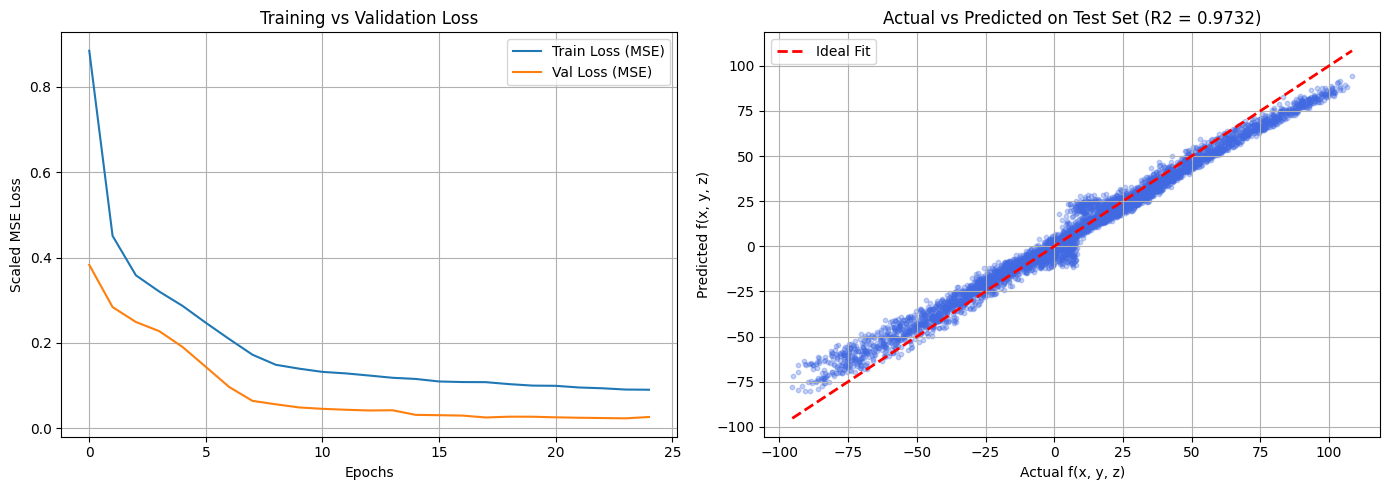

In [15]:

y_test_pred = scaler_y.inverse_transform(model_v2.predict(X_test_s))

test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Final Test Metrics -> MSE: {test_mse:.4f} | RMSE: {test_rmse:.4f} | MAE: {test_mae:.4f} | R2: {test_r2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training vs Validation Loss Curve
axes[0].plot(history_v2.history['loss'], label='Train Loss (MSE)')
axes[0].plot(history_v2.history['val_loss'], label='Val Loss (MSE)')
axes[0].set_title('Training vs Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Scaled MSE Loss')
axes[0].legend()
axes[0].grid(True)

# Predicted vs Actual Scatter Plot
axes[1].scatter(y_test, y_test_pred, alpha=0.3, s=10, color='royalblue')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[1].set_title(f'Actual vs Predicted on Test Set (R2 = {test_r2:.4f})')
axes[1].set_xlabel('Actual f(x, y, z)')
axes[1].set_ylabel('Predicted f(x, y, z)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()